# Distribuição Gamma

## Exercício 1

Gere uma amostra de uma distribuição $\operatorname{Gamma}(k,\lambda)$, com $k$ inteiro, via soma de exponenciais. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 2

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 3

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha<1$, utilizando a técnica vista em sala, isto é, usando o fato de que, se $G \sim \Gamma(\alpha+1,\lambda)$ e $U \sim \operatorname{Unif}(0,1)$ são independentes, então

$$
X = G U^{1/\alpha} \sim \Gamma(\alpha,\lambda).
$$
Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

# Distribuição Beta

## Exercício 4

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$, com $\alpha,\beta>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 5

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$ utilizando o fato de que, se

$$
G_1 \sim \Gamma(\alpha,1), \qquad G_2 \sim \Gamma(\beta,1)
$$

são independentes, então

$$
X = \frac{G_1}{G_1+G_2} \sim \operatorname{Beta}(\alpha,\beta).
$$

Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [ ]:
def f(x,lamb,alpha):
  num = (lamb ** alpha)*(x**(alpha - 1))*np.exp(-lamb*x)
  den = math.gamma(alpha)
  return num/den

In [ ]:
def g(x,mi):
  return mi*np.exp(-mi*x)

In [ ]:
lamb = 3
amostra = []
k = 100
N = 1000
for i in range(N):
  gama = []
  for i in range(k):
    u = np.random.uniform()
    exp = -(1/lamb)*np.log(1-u)
    gama.append(exp)
  amostra.append(np.sum(gama))


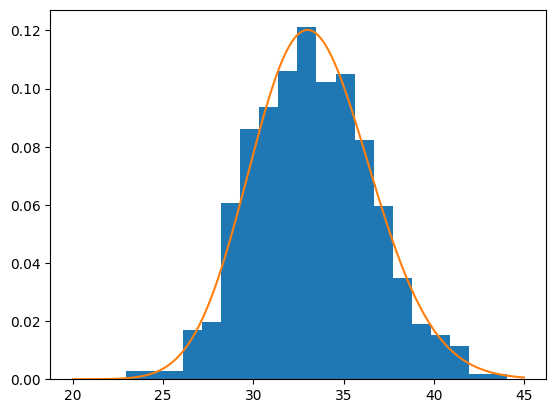

In [ ]:
plt.hist(amostra, density=True, bins = 20)

eixo = np.linspace(20,45,1000)
plt.plot(eixo, f(eixo,3,100))



In [ ]:
1

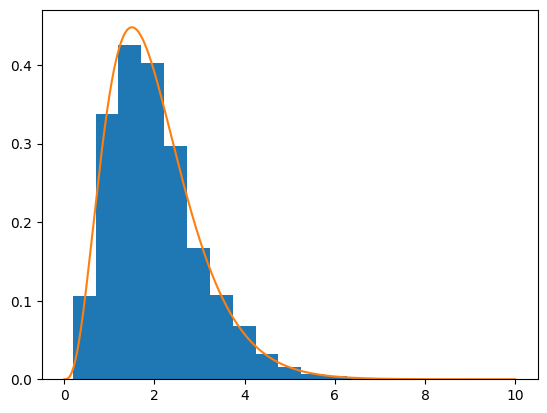

In [ ]:
plt.hist(amostra_gamma, density= True,bins = 15)
ax = np.linspace(0,10,1000)
plt.plot(ax ,f(ax,lamb,alpha) )

In [ ]:
N = 3000
amostra_gama = []

for i in range(N):
  lamb = 4
  alpha = 1.9
  mi = lamb / alpha
  xstar = (alpha - 1)/(lamb - mi)
  c = f(xstar,lamb,alpha)/g(xstar,mi)

  u = np.random.uniform()
  y = -(1/mi)*np.log(1-u)
  U = np.random.uniform()

  while c*U*g(y,mi) > f(y,lamb,alpha):
    u = np.random.uniform()
    y = -(1/mi)*np.log(1-u)
    U = np.random.uniform()

  G = y
  uni = np.random.uniform()
  X = G*((uni)**(1/(alpha-1)))
  amostra_gama.append(X)

/tmp/ipykernel_557/2125717685.py:2: RuntimeWarning: divide by zero encountered in power
  num = (lamb ** alpha)*(x**(alpha - 1))*np.exp(-lamb*x)


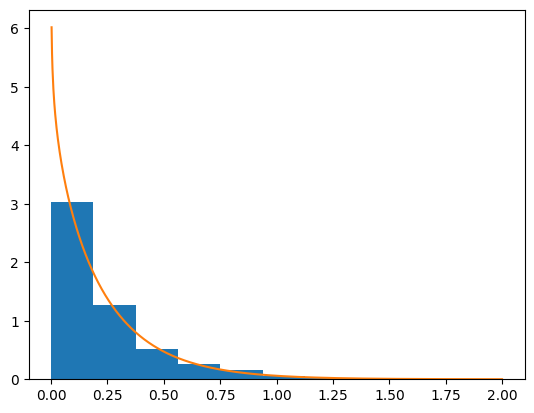

In [ ]:
plt.hist(amostra_gama, density=True, bins = 10)
ax = np.linspace(0,2,1000)
plt.plot(ax ,f(ax,lamb,alpha-1))

SIMULANDO AS BETAS

In [ ]:
def f(x,alpha,beta):
  B = math.gamma(alpha+beta)/(math.gamma(alpha)*math.gamma(beta))
  f = (x**(alpha-1) * (1-x)**(beta-1))/B
  return f

In [ ]:
alpha = 4
beta = 2
y_star = (alpha - 1)/(alpha+beta-2)

c = f(y_star,alpha,beta)

In [ ]:
amostra_beta = []
N = 8000
for i in range(N):
  y = np.random.uniform()
  u = np.random.uniform()

  while u >= f(y,alpha,beta)/c:
    y = np.random.uniform()
    u = np.random.uniform()

  x = y
  amostra_beta.append(x)

In [ ]:
amostra_betas = []
alpha = 4
beta = 2
N = 1000
for i in range(N):
  gama_alpha = []
  for i in range(alpha):
    u = np.random.uniform()
    exp = -np.log(1-u)
    gama_alpha.append(exp)
  X = np.sum(gama_alpha)
  gama_beta = []
  for i in range(beta):
    u = np.random.uniform()
    exp = -np.log(1-u)
    gama_beta.append(exp)
  Y = np.sum(gama_beta)

  Beta = X/(X+Y)
  amostra_betas.append(Beta)

Text(0.5, 1.0, 'Beta de gamas')

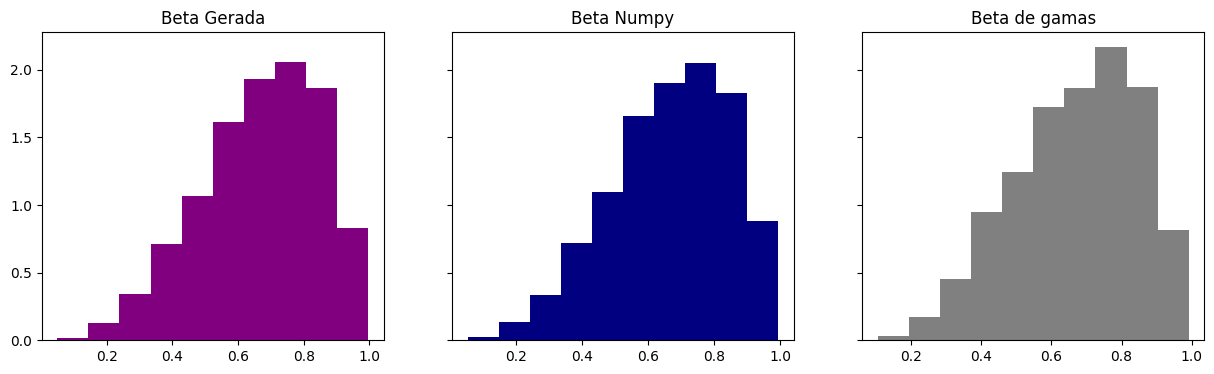

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
axs[0].hist(amostra_beta, color="purple",density = True)
axs[0].set_title("Beta Gerada")

axs[1].hist(np.random.beta(4,2,8000), color="navy", density = True)
axs[1].set_title("Beta Numpy")

axs[2].hist(amostra_betas, color="grey", density = True)
axs[2].set_title("Beta de gamas")